# Exp2 leave-one-galaxy-out analysis

This notebook keeps four evaluation domains separate: **In-Distribution Test**, **Held-Out Test**, **Raw In-Domain**, and **Raw Held-Out**. Metrics are always calculated for all four domains. Plotting the two in-domain reference domains can be disabled to focus on genuine cross-galaxy generalization.

`Held-Out Test` (`out.pt`) is the authoritative generalization result. `Raw Held-Out` independently reconstructs the same full trajectory from processed HDF5 files and is used as a preprocessing-consistency check. Their predictions are required to agree before figures and statistics are saved. RMSE, MAE, R2, and OutlierFrac are calculated in the configured transformed-target space (currently `log10(1 + SFR)`); OutlierFrac is a 0–1 fraction using an absolute transformed-target error greater than 1.

In [4]:
# Optional analysis branches: False skips dataset loading, inference, outputs, and figures.
# Both held-out branches are always analyzed and plotted.
PLOT_IN_DISTRIBUTION = False  # cached test.pt from galaxies participating in training
PLOT_IN_DOMAIN = False        # complete raw trajectories of training galaxies
ANALYSIS_BATCH_SIZE =256     # try 256 if GPU memory permits

# RESULT_DIRS 非空时只分析显式指定的目录；为空时从已完成的 Exp2 结果中自动发现。
# RESULT_NAME_CONTAINS 用于隔离实验族，避免把旧 NoFiLM 与新 NoAug 结果混在一次分析中。
RESULT_DIRS = [
    r'D:\research\ai+MACERsimulation\MACNet-v1\Results'
    r'\Exp2_Rh12x20_FiveRuns_Closure_LOO_Model075_Bands4_Freq4_Trial53Params_seed42_Final_20260914_110925'
]
RESULT_NAME_CONTAINS = ''


Analyzing Exp2_Rh12x20_FiveRuns_Closure_LOO_Model075_Bands4_Freq4_Trial53Params_seed42_Final_20260914_110925

Analyzing: Exp2_Rh12x20_FiveRuns_Closure_LOO_Model075_Bands4_Freq4_Trial53Params_seed42_Final_20260914_110925
Cache prefix: Exp2_Rh12x20_FiveRuns_Closure_LOO_disk_galaxy_model_0_75_
Analysis inference batch size: 256
[PASS] Analysis split contract: in-domain=skipped (metadata-only validation), held-out=['disk_galaxy_model_0_75']
  Skipping In-Distribution Test loading, inference, outputs, and figures.
  Skipping Raw In-Domain loading, inference, outputs, and figures.
  Predicting Raw Held-Out: disk_galaxy_model_0_75 (954 snapshots)
[PASS] Cached held-out and raw held-out trajectories agree: max |time diff|=3.815e-07 Gyr, max |prediction diff|=1.809e-08


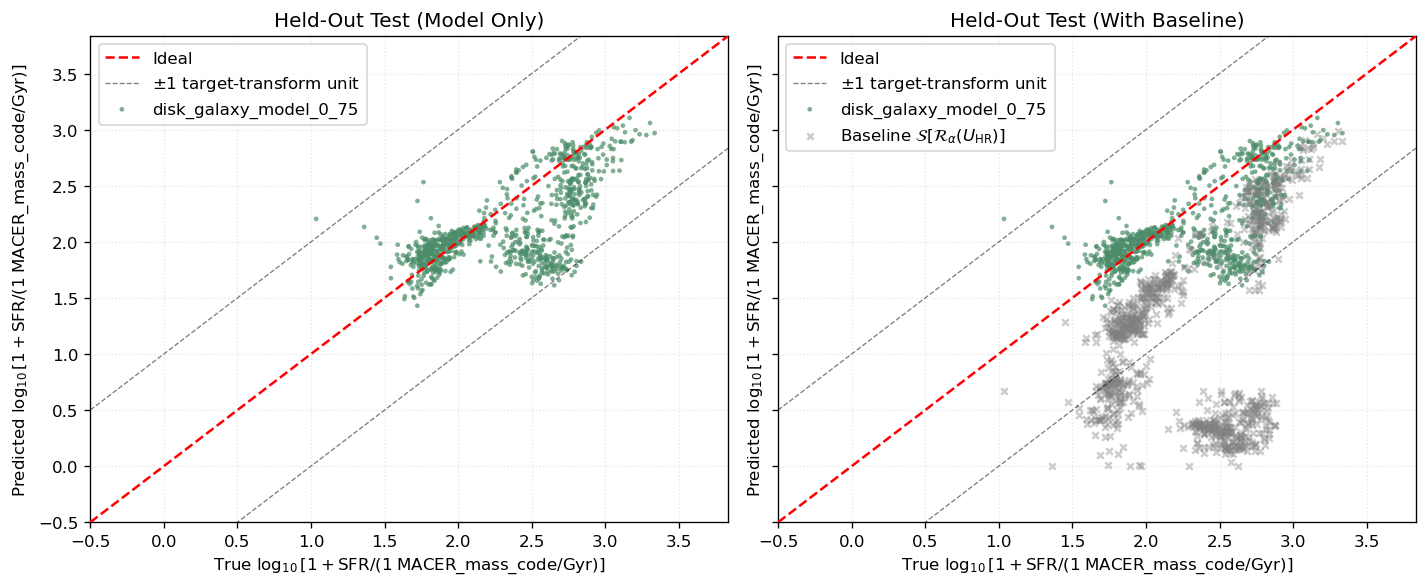

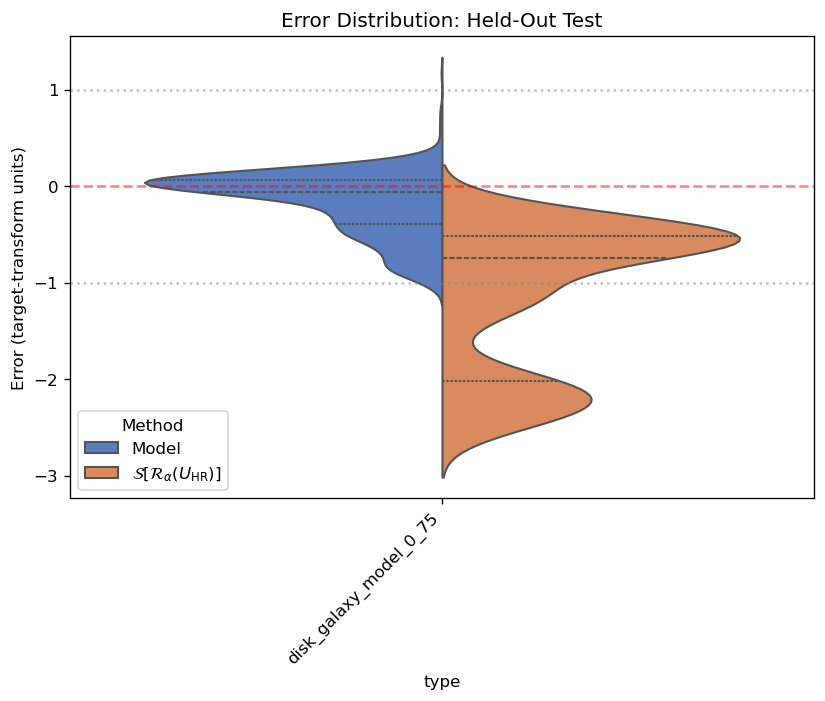

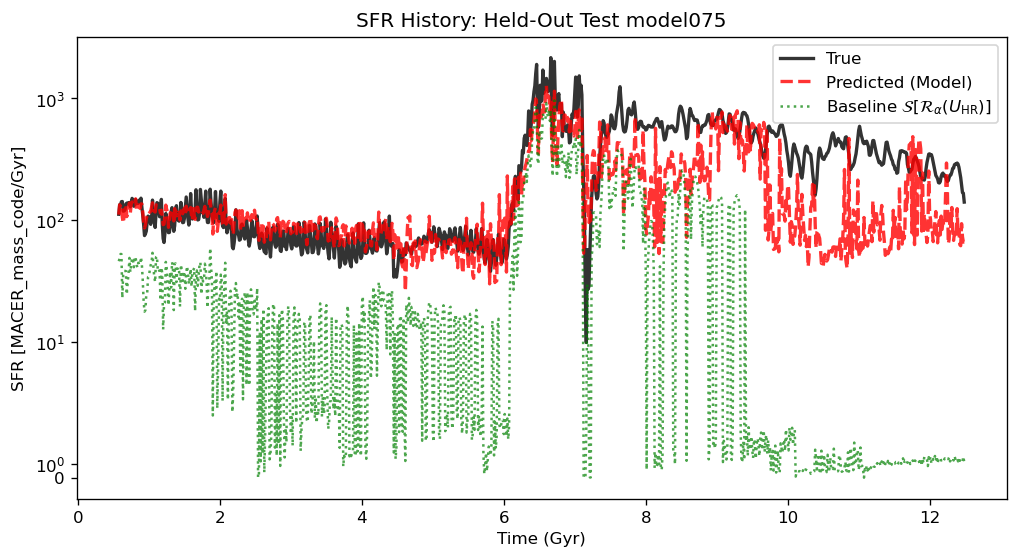

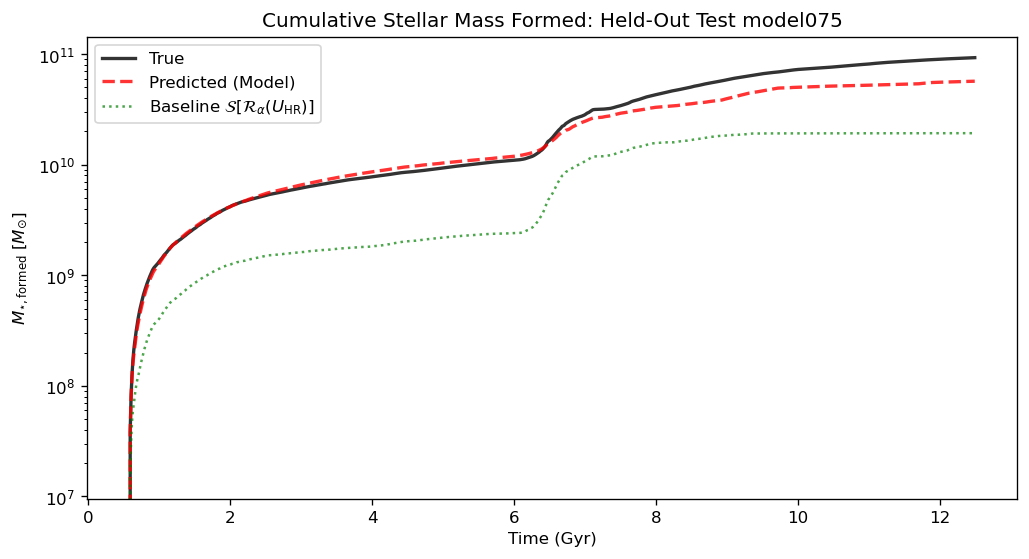

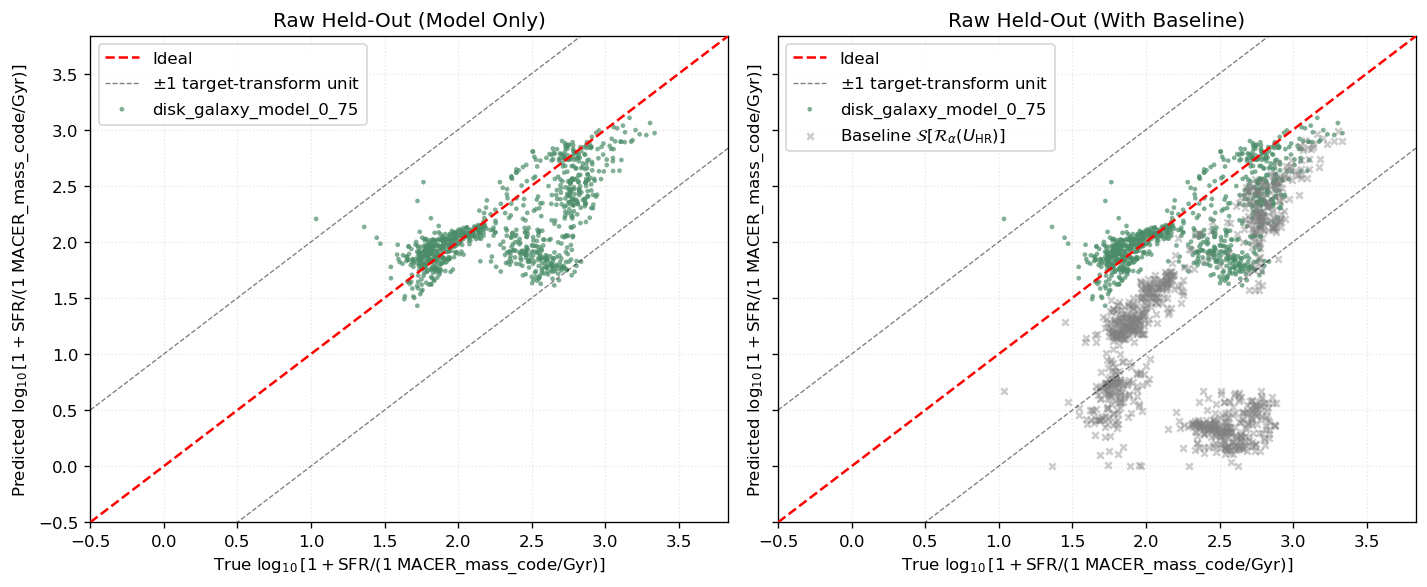

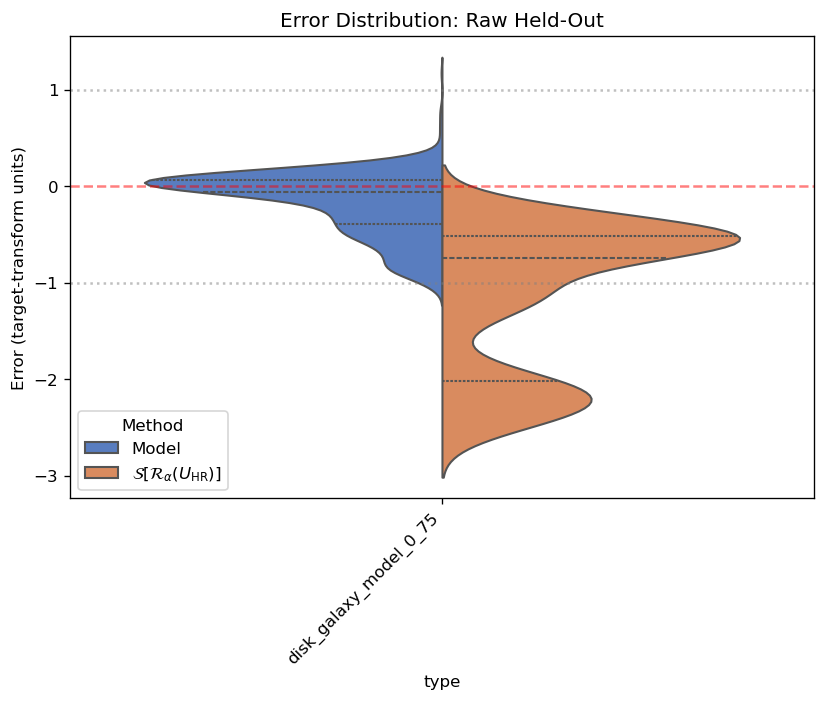

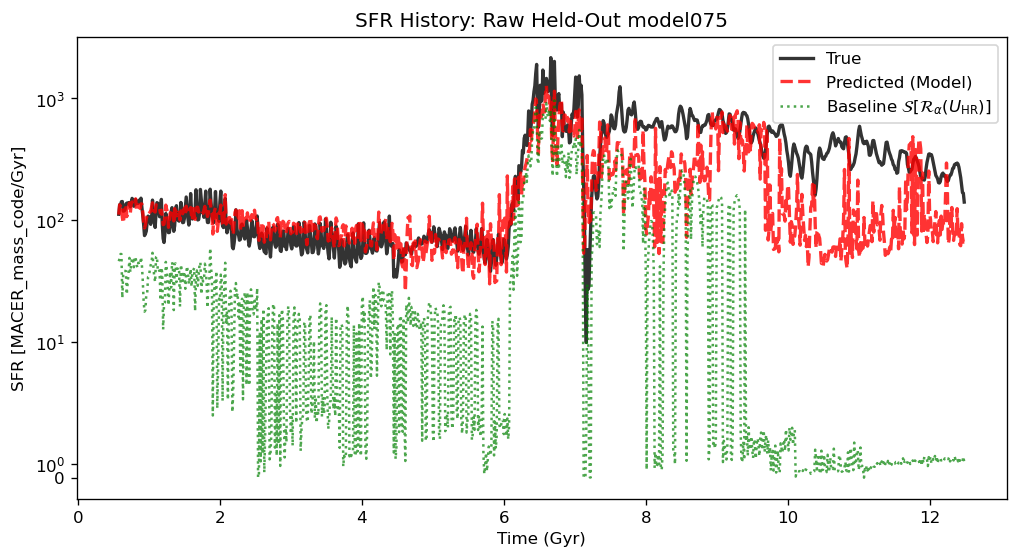

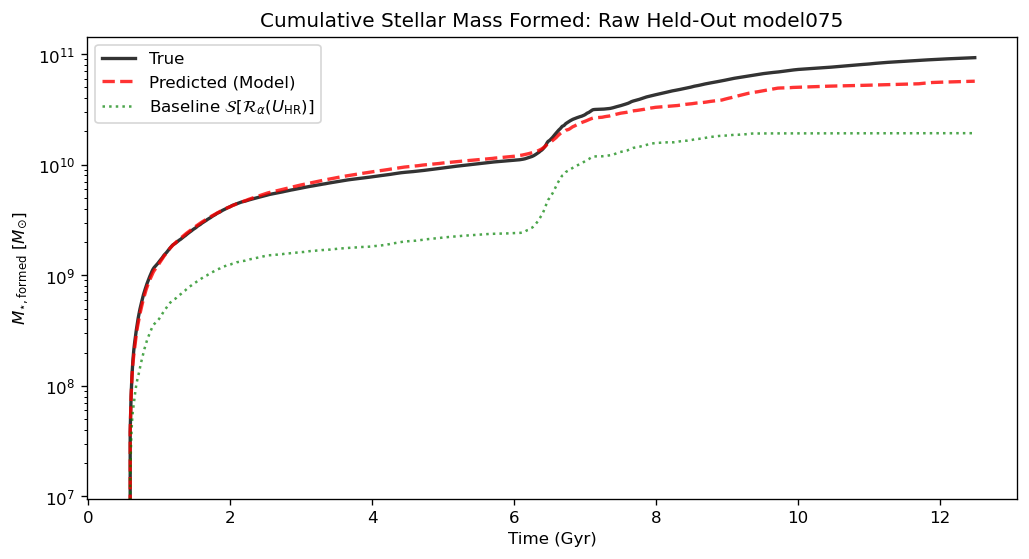

Saved domain-separated Exp2 analysis to: D:\research\ai+MACERsimulation\MACNet-v1\Results\Exp2_Rh12x20_FiveRuns_Closure_LOO_Model075_Bands4_Freq4_Trial53Params_seed42_Final_20260914_110925


,ResultDir,HeldOut,Dataset,RMSE,MAE,R2,OutlierFrac (|target error|>1),N_valid,Model_TotalPeriod_SFR_UnderestimatePct,MACERLR_TotalPeriod_SFR_UnderestimatePct
0,Exp2_Rh12x20_FiveRuns_Closure_LOO_Model075_Ban...,model075,Held-Out Test,0.370812,0.263355,0.265384,0.007338,954,38.787486,79.26263
1,Exp2_Rh12x20_FiveRuns_Closure_LOO_Model075_Ban...,model075,Raw Held-Out,0.370812,0.263355,0.265384,0.007338,954,38.787486,79.26263


In [6]:
import importlib
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display

cwd = Path.cwd().resolve()
project_root = next((p for p in (cwd, *cwd.parents) if (p / 'Experiment').is_dir() and (p / '.config').is_dir()), None)
if project_root is None:
    raise RuntimeError('Could not locate the MACNet-v1 project root.')
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from VisualScripts.ResultAnalysis import analysis_utils, analyze_exp2

# Jupyter caches imported modules. Reload both layers so this notebook always
# uses the current on-disk function signatures and metric definitions.
importlib.reload(analysis_utils)
importlib.reload(analyze_exp2)
analyze_result = analyze_exp2.analyze_result
_discover_latest_fold_results = analyze_exp2._discover_latest_fold_results

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
result_dirs = [Path(path) for path in RESULT_DIRS] if RESULT_DIRS else _discover_latest_fold_results(project_root / 'Results')
if RESULT_NAME_CONTAINS:
    result_dirs = [path for path in result_dirs if RESULT_NAME_CONTAINS in path.name]
if not result_dirs:
    raise RuntimeError('No completed leave-one-galaxy-out Exp2 results were found.')

def integrated_sfr_underestimate_percent(prediction_path):
    """按每个星系的完整时间轨迹积分；正值表示总 SFR 被低估。"""
    prediction_path = Path(prediction_path)
    if not prediction_path.exists():
        return np.nan, np.nan
    predictions = pd.read_csv(prediction_path)
    required = {'type', 'time', 'sfr_true', 'sfr_pred', 'sfr_macer_baseline'}
    missing = required.difference(predictions.columns)
    if missing:
        raise RuntimeError(f'{prediction_path} 缺少总时段 SFR 积分字段：{sorted(missing)}')

    true_total = model_total = baseline_total = 0.0
    valid_groups = 0
    for _, group in predictions.groupby('type', sort=False):
        group = group.sort_values('time').drop_duplicates('time')
        if len(group) < 2:
            continue
        time = group['time'].to_numpy(dtype=float)
        dt = np.diff(time)
        if np.any(dt <= 0):
            raise RuntimeError(f'{prediction_path} 存在非严格递增的时间坐标。')
        def trapezoid(values):
            values = np.asarray(values, dtype=float)
            return np.sum(0.5 * (values[1:] + values[:-1]) * dt)
        true_total += trapezoid(group['sfr_true'])
        model_total += trapezoid(group['sfr_pred'])
        baseline_total += trapezoid(group['sfr_macer_baseline'])
        valid_groups += 1
    if valid_groups == 0 or not np.isfinite(true_total) or true_total <= 0:
        return np.nan, np.nan
    model_underestimate = 100.0 * (true_total - model_total) / true_total
    baseline_underestimate = 100.0 * (true_total - baseline_total) / true_total
    return model_underestimate, baseline_underestimate


metric_frames = []
for result_dir in result_dirs:
    print(f'\nAnalyzing {result_dir.name}')
    metrics_path = analyze_result(
        result_dir,
        device,
        plot_in_distribution=PLOT_IN_DISTRIBUTION,
        plot_in_domain=PLOT_IN_DOMAIN,
        batch_size=ANALYSIS_BATCH_SIZE,
    )
    frame = pd.read_csv(metrics_path)
    analysis_metadata = json.loads((result_dir / 'exp2_analysis_metadata.json').read_text(encoding='utf-8'))
    # 只有完整时间轨迹才能称为“总时段”积分；随机抽取的 In-Distribution Test 不计算该量。
    full_trajectory_files = {
        'Held-Out Test': 'held_out_test_predictions.csv',
        'Raw Held-Out': 'raw_held_out_predictions.csv',
        'Raw In-Domain': 'raw_in_domain_predictions.csv',
    }
    frame['Model_TotalPeriod_SFR_UnderestimatePct'] = np.nan
    frame['MACERLR_TotalPeriod_SFR_UnderestimatePct'] = np.nan
    for row_index, dataset_name in frame['Dataset'].items():
        prediction_name = full_trajectory_files.get(dataset_name)
        if prediction_name is None:
            continue
        model_underestimate, baseline_underestimate = integrated_sfr_underestimate_percent(
            result_dir / prediction_name
        )
        frame.loc[row_index, 'Model_TotalPeriod_SFR_UnderestimatePct'] = model_underestimate
        frame.loc[row_index, 'MACERLR_TotalPeriod_SFR_UnderestimatePct'] = baseline_underestimate
    frame.insert(0, 'HeldOut', analysis_metadata['held_out_groups'][0].removeprefix('disk_galaxy_').replace('_', ''))
    frame.insert(0, 'ResultDir', result_dir.name)
    metric_frames.append(frame)

metrics_all_folds = pd.concat(metric_frames, ignore_index=True)
metrics_all_folds.to_csv(project_root / 'Results' / 'Exp2_LOO_metrics_all_folds.csv', index=False)
display(metrics_all_folds)

In [3]:
# Cross-fold generalization summary. Held-Out Test is authoritative;
# Raw Held-Out should be numerically equivalent and acts as an independent pipeline check.
held_out_metrics = metrics_all_folds[
    metrics_all_folds['Dataset'].isin(['Held-Out Test', 'Raw Held-Out'])
].copy()
numeric_columns = ['RMSE', 'MAE', 'R2', 'OutlierFrac (|target error|>1)']
cross_fold_summary = held_out_metrics.groupby('Dataset')[numeric_columns].agg(['mean', 'std', 'min', 'max'])
cross_fold_summary.to_csv(project_root / 'Results' / 'Exp2_LOO_cross_fold_summary.csv')
display(cross_fold_summary)

RMSE                               MAE                \
                   mean std       min       max      mean std       min   
Dataset                                                                   
Held-Out Test  0.296865 NaN  0.296865  0.296865  0.213142 NaN  0.213142   
Raw Held-Out   0.296865 NaN  0.296865  0.296865  0.213142 NaN  0.213142   

                               R2                          \
                    max      mean std       min       max   
Dataset                                                     
Held-Out Test  0.213142  0.529162 NaN  0.529162  0.529162   
Raw Held-Out   0.213142  0.529162 NaN  0.529162  0.529162   

              OutlierFrac (|target error|>1)                          
                                        mean std       min       max  
Dataset                                                               
Held-Out Test                       0.004193 NaN  0.004193  0.004193  
Raw Held-Out                        0.004193 NaN  0.004193  0.004193